# Geometric Curvature: Single-Organoid Walkthrough

Follow the curvature calculation in `scripts/setup_GNN_dataset.py`, with
intermediate mesh plots for **Gaussian curvature K**.
This notebook reuses the production functions and checks its final fields against
`compute_organoid_curvatures`. It does not run the batch exporter or overwrite data.

Pipeline: graph-aligned source mesh -> spectral geometry smoothing -> geometric
curvature -> HKS defect detection -> masking and inpainting -> scalar diffusion ->
Gaussian-curvature normalization -> area-weighted cell-patch averages.

The separate `test_curvature_HKS.ipynb` explores HKS as the curvature estimator.
Here, HKS is used only to detect defects.

In [1]:
from pathlib import Path
import importlib.util
import inspect
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = next(
    (p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
     if (p / "scripts/setup_GNN_dataset.py").is_file()), None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook from within the OrganoGraph repository")
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from organograph.mesh.OrganoidMesh import OrganoidMesh
from organograph.mesh.transform import ensure_mesh_graph_aligned
from organograph.mesh.curvature_mean import (
    spectral_smooth_mesh, boundary_vertices,
    compute_gaussian_curvature_angle_defect, mesh_neighbors_from_faces,
    detect_defects_hks, inpaint_by_neighbor_averaging, smooth_scalar_field_lbo,
    renormalize_gaussian_curvature_to_4pi, integrate_curvature,
    compute_organoid_curvatures, vertex_areas,
)
from organograph.graph.io import load_cell_graph
from organograph.plotting.meshes import plot_organoid_mesh

spec = importlib.util.spec_from_file_location(
    "gnn_dataset_exporter", PROJECT_ROOT / "scripts/setup_GNN_dataset.py"
)
exporter = importlib.util.module_from_spec(spec)
spec.loader.exec_module(exporter)  # Importing does not call main().

## 1. Select the Organoid and Settings

The default organoid matches the HKS notebook, but the mesh is resolved from the
**preprocessed graph metadata**, exactly as in the exporter. This avoids accidentally
using the older, differently smoothed mesh hardcoded in the HKS notebook.

Set `GRAPH_PATH_OVERRIDE` to inspect another graph, including a perturbation graph.
`TIMEPOINT` denotes its folder group (e.g. `normal` or `small` for perturbations).
The curvature defaults below are read from the exporter and its library function.

In [2]:
DATA_ROOT = Path(exporter.DATA_ROOT).resolve()
DATASET = "20251201"
TIMEPOINT = "day4p5"
LABEL_UID = "day4p5_B03_144"
GRAPH_PATH_OVERRIDE = None
GRAPH_PATH = (
    Path(GRAPH_PATH_OVERRIDE).expanduser().resolve() if GRAPH_PATH_OVERRIDE else
    DATA_ROOT / DATASET / exporter.DEFAULT_GRAPH_SUBDIR / TIMEPOINT / f"{LABEL_UID}.gpickle"
)

curvature_parameters = {
    name: parameter.default
    for name, parameter in inspect.signature(compute_organoid_curvatures).parameters.items()
    if name not in {"mesh", "return_diag"}
}
curvature_parameters.update(
    lmax=exporter.CURVATURE_LMAX,
    diffusion_smoothen_time=exporter.CURVATURE_DIFFUSION_SMOOTHEN_TIME,
)
# Edit curvature_parameters here for experiments; defaults reproduce the exporter.
N_DEFECT_EXAMPLES = 2
N_NORMAL_EXAMPLES = 4
FIT_EXAMPLE_SEED = 42
COLOR_PERCENTILE = 99.0  # Display clipping only; all calculations keep full values.
VIEW = dict(azim=-135, elev=25, projection="orthographic")
VERIFY_PRODUCTION_PARITY = True

display(pd.Series({k: v for k, v in curvature_parameters.items() if not k.startswith("mean_")},
                  name="Gaussian curvature settings").to_frame())
print("Graph:", GRAPH_PATH)

,Gaussian curvature settings
lmax,12
defect_detection,hks
defect_detection_mesh,raw
defect_tau_ref,None
defect_zmax,5.0
defect_dilation_steps,3
inpaint_iters,30
diffusion_smoothen_time,0.8
area_mode,mass
positive_defects_only,True


Graph: /home/fmoller/Projects/LearningOrganoids/NicoleData/20251201/graphs_preprocessed/day4p5/day4p5_B03_144.gpickle


## 2. Load and Align the Source Mesh

Copy the coordinate transform stored in the graph to the mesh. Do **not** also
call `normalize_inplace`, which would risk scaling twice. The source coordinates
are in micrometers. A graph scale of 10 therefore means mesh coordinates are in
units of 10 um and K in (10 um)^-2.

"Source" means the mesh linked to the graph; it may already have undergone
preprocessing. Spectral smoothing below is an additional, explicit step.

In [3]:
if not GRAPH_PATH.is_file():
    raise FileNotFoundError(GRAPH_PATH)
graph = load_cell_graph(str(GRAPH_PATH))
mesh_path = exporter.resolve_mesh_path(
    graph, str(GRAPH_PATH), str(DATA_ROOT / DATASET), TIMEPOINT,
    exporter.DEFAULT_INDEX_CSV_NAME,
)
source_mesh = OrganoidMesh(mesh_path)
source_mesh.label_uid = graph.graph.get("label_uid", GRAPH_PATH.stem)
transform_applied = ensure_mesh_graph_aligned(source_mesh, graph)
if not transform_applied:
    raise ValueError("No alignment transform applied; inspect the graph/mesh transform metadata")
if exporter.PRECOMPUTE_MESH_EIGENDECOMP:
    source_mesh._eig_decomp()

coordinate_scale = float(graph.graph["coord_transform"]["scale"])
K_UNIT = f"({coordinate_scale:g} um)^-2"
print("Mesh:", mesh_path)
print(f"Vertices: {len(source_mesh.v)}; faces: {len(source_mesh.f)}; cells: {len(graph)}")
print(f"K units: {K_UNIT}")
print(f"Convert K to um^-2 by dividing by {coordinate_scale**2:g}.")

Mesh: /home/fmoller/Projects/LearningOrganoids/NicoleData/20251201/fractal_output/day4p5/251130R0.zarr/B/03/2_zillum_registered/meshes/nnorg_corrected_smoothed_annotated_by_projection/144.vtp
Vertices: 18001; faces: 35998; cells: 1301
K units: (10 um)^-2
Convert K to um^-2 by dividing by 100.


## Plotting Helpers

All mesh plots use the existing `plot_organoid_mesh(..., backend="plotly")`
function. Gaussian-curvature maps share symmetric color limits derived from
the initial geometric estimate. Display clipping does not change any values.

In [4]:
def symmetric_limits(values):
    values = np.asarray(values, dtype=float)
    finite = np.abs(values[np.isfinite(values)])
    bound = float(np.percentile(finite, COLOR_PERCENTILE)) if finite.size else 1.0
    bound = max(bound, np.finfo(float).eps)
    return (-bound, bound)


def show_mesh(mesh, values, *, title, limits=None, signed=True,
              colorscale="RdBu_r", unit=""):
    fig = plot_organoid_mesh(
        mesh, values, backend="plotly", colorscale=colorscale,
        center_at_zero=signed, vmin=None if limits is None else limits[0],
        vmax=None if limits is None else limits[1], view=VIEW, fig_size=(750, 500),
    )
    fig.update_layout(title=dict(text=title, font=dict(size=16)), margin=dict(t=60))
    fig.update_traces(colorbar=dict(title=unit))
    fig.show(renderer="plotly_mimetype")
    return fig


def show_curvature(mesh, K, stage):
    return show_mesh(mesh, K, title=f"{stage}: Gaussian curvature K",
                     limits=K_LIMITS, unit=K_UNIT)

## 3. Spectrally Smooth the Geometry

Project mesh coordinates onto the Laplace-Beltrami eigenbasis and reconstruct
with the first `lmax**2` modes (144 for `lmax=12`). Faces and vertex indexing stay
unchanged. Rebuild the Laplacian and mass matrix on the reconstructed geometry.

In [5]:
smoothed_mesh = spectral_smooth_mesh(
    source_mesh, lmax=curvature_parameters["lmax"], recompute_operators=True,
)
np.testing.assert_array_equal(source_mesh.f, smoothed_mesh.f)
print("Coordinate modes retained:", curvature_parameters["lmax"] ** 2)

Coordinate modes retained: 144


## 4. Compute Geometric Gaussian Curvature

On the **smoothed geometry**, Gaussian curvature is the angle deficit divided
by vertex area: $K_i=(2\pi-\sum_f\theta_{if})/A_i$ for an interior vertex.
This is the uncorrected field, before defect filling, scalar diffusion,
or Gaussian renormalization.

In [6]:
area_mode = curvature_parameters["area_mode"]
K_raw = compute_gaussian_curvature_angle_defect(smoothed_mesh, area_mode=area_mode)
K_LIMITS = symmetric_limits(K_raw)
neighbors = mesh_neighbors_from_faces(smoothed_mesh)
if np.any(boundary_vertices(smoothed_mesh)):
    warnings.warn("This mesh has a boundary; the exporter's 4*pi target assumes a closed genus-0 surface")
show_curvature(smoothed_mesh, K_raw, "Geometric estimate");

## 5. Detect Defects Using HKS

By default HKS is evaluated on the **source mesh**, before the additional
spectral reconstruction. Early-time HKS slope outliers receive a robust
median/MAD score. The default threshold is 5; positive-defect gating uses
`K_raw` from the smoothed surface. Expand the mask by three edge-neighbor rings.
Vertex correspondence transfers this mask between the two geometries.

In [7]:
if curvature_parameters["defect_detection"] == "hks":
    detector_mesh = (source_mesh if curvature_parameters["defect_detection_mesh"] == "raw"
                     else smoothed_mesh)
    defect_mask, defect_score, hks_debug = detect_defects_hks(
        detector_mesh, tau_ref=curvature_parameters["defect_tau_ref"],
        zmax=curvature_parameters["defect_zmax"],
        dilation_steps=curvature_parameters["defect_dilation_steps"],
        positive_gate=K_raw if curvature_parameters["positive_defects_only"] else None,
        positive_gate_only=curvature_parameters["positive_defects_only"],
        area_mode=area_mode, return_diag=True,
    )
    defect_mask_before_dilation = hks_debug["defect_mask_pre_dilation"]
elif curvature_parameters["defect_detection"] == "none":
    defect_mask = np.zeros(len(smoothed_mesh.v), dtype=bool)
    defect_score = np.zeros(len(smoothed_mesh.v))
    defect_mask_before_dilation = defect_mask.copy()
    hks_debug = {}
else:
    raise ValueError("defect_detection must be hks or none")

show_mesh(source_mesh, defect_score, title="Early-time HKS defect score",
          limits=symmetric_limits(defect_score), unit="robust score")
show_mesh(smoothed_mesh, defect_mask_before_dilation.astype(float),
          title="Defect mask before dilation", limits=(0, 1), signed=False,
          colorscale="viridis", unit="defect")
show_mesh(smoothed_mesh, defect_mask.astype(float), title="Dilated defect mask",
          limits=(0, 1), signed=False, colorscale="viridis", unit="defect")
print(f"Flagged vertices: {defect_mask.sum()} / {len(defect_mask)} ({defect_mask.mean():.2%})")

Flagged vertices: 1175 / 18001 (6.53%)


### HKS Time Derivative

Plot the derivative of **raw HKS with respect to actual mesh time**,
$\partial_t\mathrm{HKS}(x,t)=-\sum_k\lambda_k e^{-\lambda_k t}\phi_k(x)^2$.
This differentiates the same truncated spectral expansion used by
`compute_hks`, reusing the mesh eigendecomposition. No finite differencing,
mean subtraction, or previous HKS transformation is applied.

Use 50 logarithmically spaced reference times from 0.1 to **2**; the curve panel
has that same upper x-limit. Actual mesh time is
$t=t_{ref}(L_{mesh}/13)^2$, where $L_{mesh}=\sqrt{\mathrm{surface\ area}}$.
The x-axis remains logarithmic and the derivative y-axis linear.

The first panel displays 400 sampled vertices and highlights five vertices
with the lowest interval minima. The second overlays two histograms with shared
bins: the **arithmetic mean over the sampled times** and the **signed minimum
derivative** in the displayed interval, one entry per vertex per histogram.
Because sampling is logarithmic, this mean is not a uniform-time integral.
Both statistics are restricted to reference time at most 2, not the full
time grid if a wider grid is supplied. Minimum means the smallest signed value,
not the largest magnitude.

The third panel colors the mesh by the same interval minimum derivative, using
a sequential Viridis scale spanning its observed minimum and maximum (not
centered on zero). A constant field receives a small display-range padding.
All finite curves are included, regardless of sign; nonfinite curves are gray.
Equal minima use their earliest time. The per-vertex table records the mean,
minimum, and reference/mesh time of the minimum. Defect detection is unchanged.


In [8]:
HKS_CURVE_XMAX = 2.0
HKS_CURVE_TIMES = np.geomspace(0.1, HKS_CURVE_XMAX, 50)
HKS_REFERENCE_LENGTH = 13.0
N_HKS_CURVES = 400
HKS_CURVE_SAMPLE_SEED = 42
N_HKS_DERIVATIVE_BINS = 60
N_HKS_DERIVATIVE_HIGHLIGHTS = 5


def compute_hks_time_derivative(mesh, mesh_times):
    mesh_times = np.asarray(mesh_times, dtype=float)
    if (mesh_times.ndim != 1 or not len(mesh_times)
            or not np.isfinite(mesh_times).all() or np.any(mesh_times <= 0)):
        raise ValueError("Mesh times must be a finite positive vector")
    mesh._ensure_eigendecomposition()
    eigenvalues = np.asarray(mesh.eigvals, dtype=float)
    eigenvectors = np.asarray(mesh.eigvecs, dtype=float)
    # Analytic derivative of the same truncated spectral sum as compute_hks.
    weights = -eigenvalues[:, None] * np.exp(-eigenvalues[:, None] * mesh_times[None, :])
    return (eigenvectors ** 2) @ weights


def plot_hks_derivative_summary(reference_times, curves, mesh, n_sample=400, seed=42,
                         n_bins=60, n_highlight=5, view=None, x_max=2.0):
    import plotly.graph_objects as go
    from plotly.subplots import make_subplots
    from plotly.colors import sample_colorscale

    times = np.asarray(reference_times, dtype=float)
    curves = np.asarray(curves, dtype=float)
    if len(mesh.v) != len(curves):
        raise ValueError("Mesh vertices must match HKS curves")
    if int(n_bins) < 1:
        raise ValueError("n_bins must be positive")
    if (times.ndim != 1 or len(times) < 2 or not np.isfinite(times).all()
            or np.any(times <= 0) or np.any(np.diff(times) <= 0)):
        raise ValueError("Use increasing positive finite HKS times")
    if curves.ndim != 2 or curves.shape[1] != len(times):
        raise ValueError("Curves must have shape (vertices, times)")
    if not np.isfinite(x_max) or x_max <= times[0]:
        raise ValueError("x_max must exceed the first reference time")
    interval = times <= x_max
    if np.count_nonzero(interval) < 2:
        raise ValueError("At least two time samples must lie in the displayed interval")
    times = times[interval]
    curves = curves[:, interval]
    vertices = np.flatnonzero(np.isfinite(curves).all(axis=1))
    summary = pd.DataFrame(dict(
        vertex_id=np.arange(len(curves)),
        mean_derivative=np.full(len(curves), np.nan),
        minimum_derivative=np.full(len(curves), np.nan),
        minimum_time=np.full(len(curves), np.nan),
        included=np.isfinite(curves).all(axis=1),
        highlighted=np.zeros(len(curves), dtype=bool),
    ))
    # Signed statistics over the displayed interval, with equal weight per time sample.
    summary.loc[vertices, "mean_derivative"] = curves[vertices].mean(axis=1)
    minimum_indices = np.argmin(curves[vertices], axis=1)
    summary.loc[vertices, "minimum_derivative"] = curves[vertices, minimum_indices]
    summary.loc[vertices, "minimum_time"] = times[minimum_indices]
    rng = np.random.default_rng(seed)
    sampled_ids = np.sort(rng.choice(
        vertices, size=min(max(int(n_sample), 0), len(vertices)), replace=False,
    ))
    # Select the lowest minima, resolving equal values reproducibly.
    candidates = rng.permutation(vertices)
    minima = summary.loc[candidates, "minimum_derivative"].to_numpy()
    highlights = candidates[np.argsort(minima, kind="stable")][:max(int(n_highlight), 0)]
    summary.loc[highlights, "highlighted"] = True

    fig = make_subplots(
        rows=1, cols=3, specs=[[{"type": "xy"}, {"type": "xy"}, {"type": "scene"}]],
        column_widths=[0.34, 0.30, 0.36], horizontal_spacing=0.055,
        subplot_titles=[f"HKS derivative: {len(sampled_ids)} sampled vertices",
                        f"Derivative mean and minimum: {len(vertices)} vertices",
                        "Minimum derivative in interval"],
    )
    for vertex in sampled_ids:
        fig.add_trace(go.Scatter(
            x=times, y=curves[vertex], mode="lines",
            line=dict(width=0.5, color="#7b8794"), opacity=0.25,
            showlegend=False, hoverinfo="skip",
        ), row=1, col=1)
    colors = ["#d62728", "#9467bd", "#ff7f0e", "#17becf", "#111111"]
    for index, vertex in enumerate(highlights):
        color = colors[index % len(colors)]
        name = f"Vertex {vertex}"
        fig.add_trace(go.Scatter(
            x=times, y=curves[vertex], mode="lines", name=name,
            line=dict(width=2.5, color=color), legendgroup=str(vertex),
        ), row=1, col=1)
        fig.add_trace(go.Scatter(
            x=[summary.loc[vertex, "minimum_time"]],
            y=[summary.loc[vertex, "minimum_derivative"]],
            mode="markers", marker=dict(size=7, color=color),
            name=name, legendgroup=str(vertex), showlegend=False,
        ), row=1, col=1)
    fig.add_hline(y=0, line_color="gray", line_dash="dash", line_width=0.8, row=1, col=1)

    mean_values = summary.loc[vertices, "mean_derivative"].to_numpy()
    minimum_values = summary.loc[vertices, "minimum_derivative"].to_numpy()
    edges = np.histogram_bin_edges(np.r_[mean_values, minimum_values], bins=int(n_bins))
    for values, name, color in [(mean_values, "Mean derivative", "#2077b4"),
                                 (minimum_values, "Minimum derivative", "#d55e00")]:
        counts, _ = np.histogram(values, bins=edges)
        fig.add_trace(go.Bar(
            x=(edges[:-1] + edges[1:]) / 2, y=counts, width=np.diff(edges),
            marker=dict(color=color, line=dict(color="white", width=0.4)),
            opacity=0.6, name=name,
        ), row=1, col=2)

    minimum_values = summary["minimum_derivative"].to_numpy()
    included = summary["included"].to_numpy()
    color_min = float(minimum_values[included].min()) if included.any() else 0.0
    color_max = float(minimum_values[included].max()) if included.any() else 1.0
    if color_min == color_max:
        padding = max(abs(color_min), 1.0) * 1e-6
        color_min, color_max = color_min - padding, color_max + padding
    panel = plot_organoid_mesh(mesh, backend="plotly", view=view,
                               center_at_zero=False, show_colorbar=False)
    vertex_colors = np.full(len(mesh.v), "rgb(190,190,190)", dtype=object)
    if included.any():
        positions = (minimum_values[included] - color_min) / (color_max - color_min)
        vertex_colors[included] = sample_colorscale("Viridis", positions.tolist())
    trace = panel.data[0]
    trace.update(
        color=None, vertexcolor=vertex_colors.tolist(), customdata=minimum_values,
        hovertemplate="Vertex: %{pointNumber}<br>Minimum derivative: %{customdata:.3g}<extra></extra>",
    )
    fig.add_trace(trace, row=1, col=3)
    fig.add_trace(go.Scatter3d(
        x=[None, None], y=[None, None], z=[None, None], mode="markers",
        marker=dict(color=[color_min, color_max], colorscale="Viridis",
                    cmin=color_min, cmax=color_max,
                    showscale=True, colorbar=dict(
                        title="Minimum derivative", len=0.75, thickness=14)),
        showlegend=False, hoverinfo="skip", name="Minimum-derivative color scale",
    ), row=1, col=3)
    for index, vertex in enumerate(highlights):
        point = np.asarray(mesh.v)[vertex]
        fig.add_trace(go.Scatter3d(
            x=[point[0]], y=[point[1]], z=[point[2]], mode="markers",
            marker=dict(size=5, color=colors[index % len(colors)]),
            name=f"Vertex {vertex}", legendgroup=str(vertex), showlegend=False,
        ), row=1, col=3)
    scene = panel.layout.scene.to_plotly_json()
    scene["camera"]["projection"] = dict(type=(view or {}).get("projection", "orthographic"))
    fig.update_scenes(scene, row=1, col=3)
    fig.update_xaxes(type="log", range=[np.log10(times[0]), np.log10(x_max)],
                     title_text="Reference HKS time", row=1, col=1)
    fig.update_xaxes(type="linear", title_text="dHKS/dt", row=1, col=2)
    fig.update_yaxes(type="linear", title_text="dHKS/dt", row=1, col=1)
    fig.update_yaxes(title_text="Number of vertices", row=1, col=2)
    fig.update_layout(
        width=1700, height=550, template="plotly_white", barmode="overlay",
        margin=dict(l=65, r=100, t=70, b=100),
        legend=dict(orientation="h", x=0, y=-0.22),
    )
    fig.update_annotations(font_size=13)
    return fig, summary, sampled_ids


hks_curve_mesh = (source_mesh if curvature_parameters["defect_detection_mesh"] == "raw"
                  else smoothed_mesh)
hks_curve_length = np.sqrt(np.sum(hks_curve_mesh.vertex_areas()))
hks_curve_mesh_times = HKS_CURVE_TIMES * (hks_curve_length / HKS_REFERENCE_LENGTH)**2
hks_time_derivative = compute_hks_time_derivative(hks_curve_mesh, hks_curve_mesh_times)
hks_curve_figure, hks_vertex_derivative_table, sampled_hks_vertices = plot_hks_derivative_summary(
    HKS_CURVE_TIMES, hks_time_derivative, hks_curve_mesh,
    n_sample=N_HKS_CURVES, seed=HKS_CURVE_SAMPLE_SEED,
    n_bins=N_HKS_DERIVATIVE_BINS, n_highlight=N_HKS_DERIVATIVE_HIGHLIGHTS,
    view=VIEW, x_max=HKS_CURVE_XMAX,
)
hks_vertex_derivative_table["minimum_mesh_time"] = (
    hks_vertex_derivative_table["minimum_time"] * (hks_curve_length / HKS_REFERENCE_LENGTH)**2
)
hks_curve_figure.show(renderer="plotly_mimetype")
print(f"Histograms include {hks_vertex_derivative_table['included'].sum()} / {len(hks_vertex_derivative_table)} vertices")
display(hks_vertex_derivative_table.loc[hks_vertex_derivative_table["highlighted"]])


Histograms include 18001 / 18001 vertices


,vertex_id,mean_derivative,minimum_derivative,minimum_time,included,highlighted,minimum_mesh_time
17326,17326,-0.042440,-0.173445,0.1,True,True,0.549922
17327,17327,-0.042693,-0.174844,0.1,True,True,0.549922
17336,17336,-0.042435,-0.173682,0.1,True,True,0.549922
17412,17412,-0.042410,-0.173634,0.1,True,True,0.549922
17413,17413,-0.042418,-0.173728,0.1,True,True,0.549922


### HKS Fit Examples

Show the actual early-time fits used by the defect detector for up to two defect
vertices and four normal vertices. Defects are sampled from the **pre-dilation**
mask, so they are genuine detector hits rather than neighbors added by dilation.
Normal examples lie outside the final mask and below the score threshold.
Sampling is reproducible; fewer examples are shown if a category is unavailable.

Each panel shows only the seven lowest HKS timepoints on a linear time axis,
highlighting the selected fit samples and clipping the saved fitted line to this
displayed interval. The fits and their reported fitting intervals are unchanged;
no fitting is repeated.

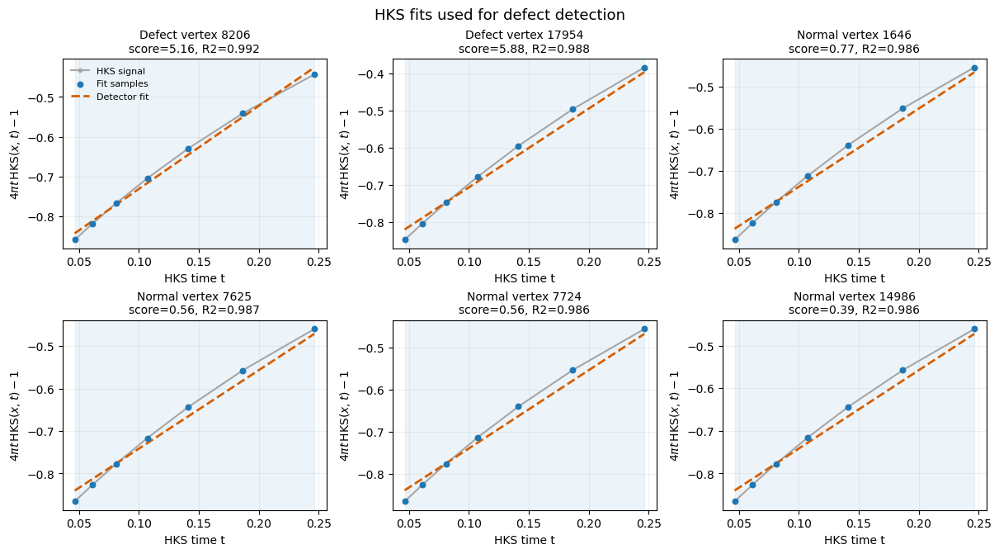

,kind,vertex,score,r2,slope,intercept,n_fit_points,fit_t_start,fit_t_end
0,defect,8206,5.163442,0.991983,2.087676,-0.940292,7,0.046468,0.246543
1,defect,17954,5.883089,0.987935,2.125182,-0.919749,8,0.046468,0.325598
2,normal,1646,0.765117,0.985976,1.858446,-0.923382,8,0.046468,0.325598
3,normal,7625,0.561858,0.986810,1.847853,-0.926392,8,0.046468,0.325598
4,normal,7724,0.559131,0.986031,1.847711,-0.923988,8,0.046468,0.325598
5,normal,14986,0.394932,0.986387,1.839153,-0.925577,8,0.046468,0.325598


Displayed examples: {'defect': 2, 'normal': 4}


In [9]:
def select_hks_fit_examples(debug, n_defects=2, n_normal=4, seed=42):
    if not debug:
        return []
    valid = (np.isfinite(debug["early_slope"]) & np.isfinite(debug["early_intercept"])
             & np.isfinite(debug["early_r2"]) & np.isfinite(debug["defect_score"])
             & np.isfinite(debug["fit_signal"]).all(axis=1))
    pools = {
        "defect": np.flatnonzero(valid & debug["defect_mask_pre_dilation"]),
        "normal": np.flatnonzero(valid & ~debug["defect_mask"]
                                 & (debug["defect_score"] <= debug["zmax"])),
    }
    rng = np.random.default_rng(seed)
    examples = []
    for kind, requested in [("defect", n_defects), ("normal", n_normal)]:
        count = min(max(int(requested), 0), len(pools[kind]))
        ids = rng.choice(pools[kind], size=count, replace=False)
        examples.extend((kind, int(vertex)) for vertex in sorted(ids))
    return examples


def plot_hks_fit_examples(debug, examples):
    if not examples:
        return None, pd.DataFrame()
    ncols = min(3, len(examples))
    nrows = int(np.ceil(len(examples) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.0 * ncols, 3.3 * nrows),
                             squeeze=False, constrained_layout=True)
    times = np.asarray(debug["ts"])
    display_times = times[:7]
    records = []
    for index, (kind, vertex) in enumerate(examples):
        ax = axes.flat[index]
        end = int(debug["early_end_idx"][vertex])
        fit_times = times[:end + 1]
        visible_fit_times = fit_times[:7]
        slope = float(debug["early_slope"][vertex])
        intercept = float(debug["early_intercept"][vertex])
        signal = np.asarray(debug["fit_signal"])[vertex]
        score = float(debug["defect_score"][vertex])
        r2 = float(debug["early_r2"][vertex])
        ax.plot(display_times, signal[:7], "o-", color="0.65", markersize=3, label="HKS signal")
        ax.scatter(visible_fit_times, signal[:len(visible_fit_times)], color="#2077b4", s=22,
                   zorder=3, label="Fit samples")
        dense_times = np.linspace(visible_fit_times[0], visible_fit_times[-1], 100)
        ax.plot(dense_times, slope * dense_times + intercept, "--",
                color="#d55e00", linewidth=2, label="Detector fit")
        ax.axvspan(visible_fit_times[0], visible_fit_times[-1], color="#2077b4", alpha=0.08)
        ax.set_xscale("linear")
        ax.set_title(f"{kind.capitalize()} vertex {vertex}\nscore={score:.2f}, R2={r2:.3f}", fontsize=10)
        ax.set_xlabel("HKS time t")
        ax.set_ylabel(r"$4\pi t\,\mathrm{HKS}(x,t)-1$")
        ax.grid(alpha=0.2)
        if index == 0:
            ax.legend(fontsize=8, frameon=False)
        records.append(dict(kind=kind, vertex=vertex, score=score, r2=r2,
                            slope=slope, intercept=intercept, n_fit_points=end + 1,
                            fit_t_start=float(fit_times[0]), fit_t_end=float(fit_times[-1])))
    for ax in list(axes.flat)[len(examples):]:
        ax.set_visible(False)
    fig.suptitle("HKS fits used for defect detection", fontsize=13)
    return fig, pd.DataFrame(records)


fit_examples = select_hks_fit_examples(
    hks_debug, N_DEFECT_EXAMPLES, N_NORMAL_EXAMPLES, FIT_EXAMPLE_SEED,
)
fit_figure, fit_example_table = plot_hks_fit_examples(hks_debug, fit_examples)
if fit_figure is None:
    print("No HKS fit examples available (detection disabled or no finite fits).")
else:
    plt.show()
    plt.close(fit_figure)
    display(fit_example_table)
    print("Displayed examples:", fit_example_table.groupby("kind").size().to_dict())

### HKS Slope Distribution

The histogram includes all finite saved early-time slopes (one per mesh vertex).
The dashed line is the detector's score threshold expressed in slope units:
$b_{cut}=\mathrm{median}(b)+z_{max}\,1.4826\,\mathrm{MAD}(b)$.
As in the detector, a zero or nonfinite MAD scale falls back to the standard
deviation, then to 1 if necessary. Only slopes strictly above the cutoff qualify.
Highlighted defects are those retained **before dilation**, including the
positive-curvature gate when enabled; exceeding the slope cutoff alone does
not necessarily mark a vertex as a defect. The existing fits are not recomputed.

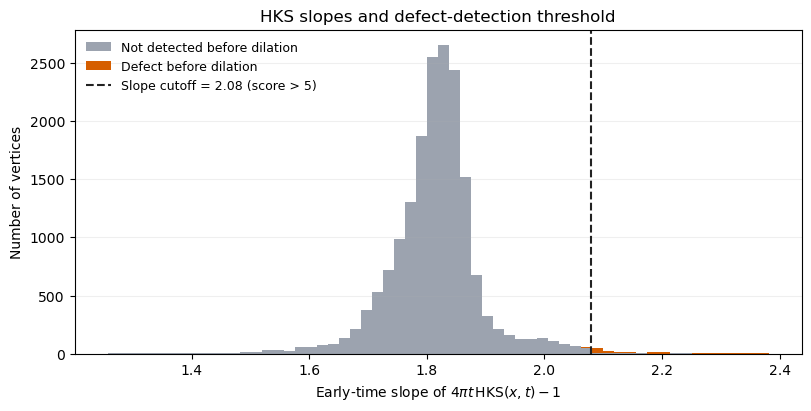

Defect slope cutoff: 2.07916


In [10]:
def plot_hks_slope_distribution(debug, bins=60):
    if not debug:
        return None, np.nan
    slopes = np.asarray(debug["early_slope"], dtype=float)
    finite = np.isfinite(slopes)
    if not finite.any():
        return None, np.nan
    # Match robust_zscore, including its degenerate-scale fallbacks.
    median = np.nanmedian(slopes)
    scale = 1.4826 * np.nanmedian(np.abs(slopes - median))
    if not np.isfinite(scale) or scale <= 0:
        scale = np.nanstd(slopes)
    if not np.isfinite(scale) or scale <= 0:
        scale = 1.0
    zmax = float(debug["zmax"])
    cutoff = median + zmax * scale
    defects = np.asarray(debug["defect_mask_pre_dilation"], dtype=bool)
    edges = np.histogram_bin_edges(slopes[finite], bins=bins)
    fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
    ax.hist([slopes[finite & ~defects], slopes[finite & defects]],
            bins=edges, stacked=True, color=["#9ca3af", "#d55e00"],
            label=["Not detected before dilation", "Defect before dilation"])
    ax.axvline(cutoff, color="#222222", linestyle="--", linewidth=1.5,
               label=f"Slope cutoff = {cutoff:.3g} (score > {zmax:g})")
    ax.set_xlabel(r"Early-time slope of $4\pi t\,\mathrm{HKS}(x,t)-1$")
    ax.set_ylabel("Number of vertices")
    ax.set_title("HKS slopes and defect-detection threshold")
    ax.legend(frameon=False, fontsize=9)
    ax.grid(axis="y", alpha=0.2)
    return fig, cutoff


slope_figure, slope_cutoff = plot_hks_slope_distribution(hks_debug)
if slope_figure is None:
    print("No finite HKS slopes available (detection disabled or invalid fits).")
else:
    plt.show()
    plt.close(slope_figure)
    print(f"Defect slope cutoff: {slope_cutoff:.6g}")

## 6. Curvature After Inpainting and Diffusion

Fill masked vertices using the production neighbor-averaging routine, then
smooth the resulting Gaussian-curvature field with one implicit diffusion step:
$(M+tL)K_{new}=MK_{inpainted}$, using the exporter's `t=0.8` default.
Only the combined result is plotted; neither masking nor inpainting alone is shown.

In [11]:
K_inpainted = inpaint_by_neighbor_averaging(
    K_raw, defect_mask, neighbors, n_iter=curvature_parameters["inpaint_iters"],
)
np.testing.assert_array_equal(K_inpainted[~defect_mask], K_raw[~defect_mask])
if not np.isfinite(K_inpainted).all():
    raise ValueError("Inpainting left nonfinite values; inspect the defect mask before diffusion")
K_diffused = smooth_scalar_field_lbo(
    smoothed_mesh, K_inpainted,
    diffusion_time=curvature_parameters["diffusion_smoothen_time"], n_steps=1,
)
show_curvature(smoothed_mesh, K_diffused, "After inpainting and diffusion");

## 7. Normalize Gaussian Curvature

Multiply K by $4\pi/\int K\,dA$, using **smoothed-mesh** vertex areas.
The $4\pi$ target assumes a closed, genus-zero organoid surface. A matching integral alone does not establish local accuracy.

In [12]:
K_final, renormalization = renormalize_gaussian_curvature_to_4pi(
    smoothed_mesh, K_diffused, area_mode=area_mode,
)
show_curvature(smoothed_mesh, K_final, "Final vertex field")
display(pd.Series(renormalization, name="Gaussian normalization").to_frame())

stages = {"geometric": K_raw, "inpainted_and_diffused": K_diffused, "final": K_final}
stage_rows = []
for stage, values in stages.items():
    finite = values[np.isfinite(values)]
    stage_rows.append(dict(
        stage=stage, n_nonfinite=int((~np.isfinite(values)).sum()),
        minimum=float(finite.min()) if finite.size else np.nan,
        maximum=float(finite.max()) if finite.size else np.nan,
        surface_integral=integrate_curvature(smoothed_mesh, values, area_mode=area_mode),
    ))
stage_diagnostics = pd.DataFrame(stage_rows)
display(stage_diagnostics)

,Gaussian normalization
gaussian_renormalized,True
gaussian_renormalization_target,12.566371
gaussian_integral_before_renormalization,11.45387
gaussian_integral_after_renormalization,12.566371
gaussian_renormalization_scale,1.097129


,stage,n_nonfinite,minimum,maximum,surface_integral
0,geometric,0,-6.803574,2.743569,12.566371
1,inpainted_and_diffused,0,-0.490877,0.233422,11.453870
2,final,0,-0.538556,0.256094,12.566371


## 8. Check Against the Production Function

Run the unmodified production function on the same aligned source mesh and
parameters. Compare the raw Gaussian curvature, defect mask, and final K, rather than
comparing with an older saved dataset whose settings may differ.

In [13]:
if VERIFY_PRODUCTION_PARITY:
    K_reference, _, reference_debug = compute_organoid_curvatures(
        source_mesh, **curvature_parameters, return_diag=True,
    )
    np.testing.assert_allclose(K_raw, reference_debug["gaussian_curvature_raw"], rtol=1e-10, atol=1e-12)
    np.testing.assert_array_equal(defect_mask, reference_debug["defect_mask"])
    np.testing.assert_allclose(K_final, K_reference, rtol=1e-10, atol=1e-12)
    print("PASS: staged Gaussian curvature results match compute_organoid_curvatures.")
else:
    print("Production parity check disabled.")

PASS: staged Gaussian curvature results match compute_organoid_curvatures.


## 9. Average Curvature Over Cell Patches

The exporter builds Dijkstra-based Voronoi patches from projected cell centers
on the **source mesh**, and uses **source-mesh areas** for averaging:
$K_{cell}=\sum_{i\in patch} A_i K_i/\sum_{i\in patch} A_i$.
Vertex indices transfer the final fields from the smoothed surface.

Cells with zero patch area are removed and the graph is reindexed. The plots
below color source-mesh vertices by their owner's patch-average value; rendering
may interpolate at boundaries between patches. No marker exclusivity is applied.

In [14]:
cell_curvature, cell_patch_area, vertex_owner, _, proj_vertex_ids = (
    exporter.assign_patch_curvature_and_area(source_mesh, graph, K_final)
)
markers = exporter.extract_marker_matrix(graph)
pruned = exporter.prune_zero_area_nodes(
    graph, markers, cell_curvature, cell_patch_area, proj_vertex_ids, vertex_owner,
)
if not np.isfinite(pruned["y"]).all():
    raise ValueError("Nonfinite curvature in retained cell patches")
cell_table = pd.DataFrame({
    "source_node_id": pruned["kept_node_ids"],
    "node_id": np.arange(len(pruned["y"])),
    "gaussian_curvature": pruned["y"][:, 0],
    "patch_area": pruned["patch_area"],
})
owners = pruned["vertex_owner"]
owned = (owners >= 0) & (owners < len(pruned["y"]))
K_patch_mesh = np.full(len(source_mesh.v), np.nan)
K_patch_mesh[owned] = pruned["y"][owners[owned], 0]

show_curvature(source_mesh, K_patch_mesh, "Cell-patch averages on source mesh")

source_areas = vertex_areas(source_mesh, area_mode="mass")
patch_integral_K = float(np.sum(pruned["y"][:, 0] * pruned["patch_area"]))
source_integral_K = float(np.sum(K_final[owned] * source_areas[owned]))
np.testing.assert_allclose(patch_integral_K, source_integral_K, rtol=1e-10, atol=1e-12)
print(f"Retained cells: {len(cell_table)} / {len(graph)}; zero-area cells removed: {pruned['num_deleted']}")
print(f"Meets exporter MIN_NODES={exporter.MIN_NODES}: {len(cell_table) >= exporter.MIN_NODES}")
print("Gaussian integral on source patches:", patch_integral_K)
print("Gaussian integral on smoothed surface:", integrate_curvature(smoothed_mesh, K_final, area_mode=area_mode))
display(cell_table.head(10))

Retained cells: 1301 / 1301; zero-area cells removed: 0
Meets exporter MIN_NODES=50: True
Gaussian integral on source patches: 10.959328367803177
Gaussian integral on smoothed surface: 12.566370614359172


,source_node_id,node_id,gaussian_curvature,patch_area
0,0,0,0.097283,0.596579
1,1,1,-0.095906,0.713208
2,2,2,-0.040496,0.754190
3,3,3,0.122861,1.961335
4,4,4,0.062793,0.693364
5,5,5,0.022546,2.123514
6,6,6,0.006343,1.408849
7,7,7,0.114786,0.956359
8,8,8,0.020656,0.997235
9,9,9,0.023418,0.976055


The patch integral need not equal 4*pi: the normalization used smoothed-surface
areas, whereas cell-patch averaging uses source-surface areas. This distinction
follows the exporter exactly. The final per-cell target array is `pruned["y"]`,
with a single Gaussian-curvature column. Intermediate arrays, the
reindexed graph, and `cell_table` remain available in memory; no dataset is saved.

## 9. Curvature Comparison

Compare the initial geometric estimate (`K_raw`), the final corrected and
normalized vertex field (`K_final`), and the cell-patch averages (`K_patch_mesh`).
The first two use the spectrally smoothed geometry; the patch field uses the
source geometry, as in the exporter. All panels share a camera, spatial bounds,
and one symmetric `RdBu_r` color scale with limits at plus/minus 1.2 times
the maximum absolute finite final curvature (`K_final`).
Color clipping is for display only and does not change the curvature values.

In [15]:
def plot_curvature_comparison(stages, limits, unit, view):
    from plotly.subplots import make_subplots

    fig = make_subplots(
        rows=1, cols=len(stages), specs=[[{"type": "scene"} for _ in stages]],
        subplot_titles=[title for title, _, _ in stages], horizontal_spacing=0.02,
    )
    vertices = np.concatenate([np.asarray(mesh.v) for _, mesh, _ in stages])
    lower, upper = vertices.min(axis=0), vertices.max(axis=0)
    padding = np.maximum(0.03 * (upper - lower), 1e-6)
    for column, (_, mesh, values) in enumerate(stages, start=1):
        panel = plot_organoid_mesh(
            mesh, values, backend="plotly", colorscale="RdBu_r",
            center_at_zero=True, vmin=limits[0], vmax=limits[1],
            show_colorbar=False, view=view,
        )
        for trace in panel.data:
            trace.update(coloraxis="coloraxis")
            fig.add_trace(trace, row=1, col=column)
        scene = panel.layout.scene.to_plotly_json()
        scene["camera"]["projection"] = dict(type=view.get("projection", "orthographic"))
        for axis, low, high, pad in zip("xyz", lower, upper, padding):
            scene[f"{axis}axis"].update(range=[low - pad, high + pad], autorange=False)
        fig.update_scenes(scene, row=1, col=column)
    fig.update_layout(
        width=1350, height=500, margin=dict(l=0, r=100, b=0, t=80),
        title="Gaussian curvature: initial, final, and cell-patch averaged",
        coloraxis=dict(colorscale="RdBu_r", cmin=limits[0], cmax=limits[1],
                       cauto=False, cmid=0, colorbar=dict(title=unit, len=0.8)),
        showlegend=False,
    )
    return fig


comparison_bound = 1.2 * np.max(np.abs(K_final[np.isfinite(K_final)]))
comparison_figure = plot_curvature_comparison(
    [("Initial", smoothed_mesh, K_raw),
     ("Final", smoothed_mesh, K_final),
     ("Cell-patch averaged", source_mesh, K_patch_mesh)],
    limits=(-comparison_bound, comparison_bound), unit=K_UNIT, view=VIEW,
)
comparison_figure.show(renderer="plotly_mimetype")